# Frames and joints

Machines are chains of parts that carry other parts: an X carriage carries the Y carriage,
which carries the Z slider and the tool. minigeo models this with **frames**: coordinate
systems that form a tree. A **joint** is a frame whose position on its parent is set by one
number, its `value`:

* `frame.prismatic(axis)` slides along an axis (`value` is a distance),
* `frame.revolute(axis)` turns about an axis (`value` is an angle in degrees),
* `frame.fixed()` does not move relative to its parent.

Geometry is built as usual, in world coordinates with anchors, and then **attached** to the
frame that carries it. Setting a joint's `value` moves everything after it in the chain.

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/asteppke/minigeo/HEAD?labpath=examples%2Fjoints.ipynb) [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/asteppke/minigeo/blob/main/examples/joints.ipynb)

In [1]:
# On Google Colab, install minigeo first (elsewhere this cell does nothing)
import sys

if "google.colab" in sys.modules:
    %pip install -q "minigeo[all] @ git+https://github.com/asteppke/minigeo"

## 1. A hinge

A revolute joint turns about its axis through the point `at`. The arm is built where it is at
`value = 0` and attached; `hinge.value = 60` turns it to 60°. Values are absolute: setting the
same value always gives the same picture.

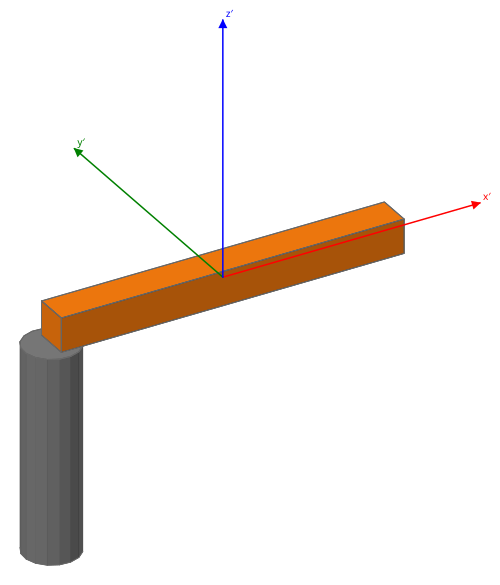

In [2]:
from minigeo import Box, Cylinder, Frame, Scene

scene = Scene()
post = scene.add(Cylinder([0, 0, 0], radius=0.08, height=0.6), fill="gray")

hinge = Frame().revolute("z", at=post.anchor("top"), limits=(-90, 90))
arm = Box(post.anchor("top"), size=(1, 0.1, 0.1), anchor="bottom left")
scene.add(hinge.attach(arm), fill="C1", frame=True)

hinge.value = 60
scene

## 2. A serial XYZ stage

X slides along the base, Y along the X carriage, Z up and down the column. Each part is
attached to the joint that carries it: the column moves with Y, so it is attached to `y`,
while the slider and tool are attached to `z`. A fixed frame `tip` marks the tool tip, so its
position can be asked for at any time. The same code is in `examples/xyz_stage.py`.

tool tip at [-0.05 -0.1   0.27]


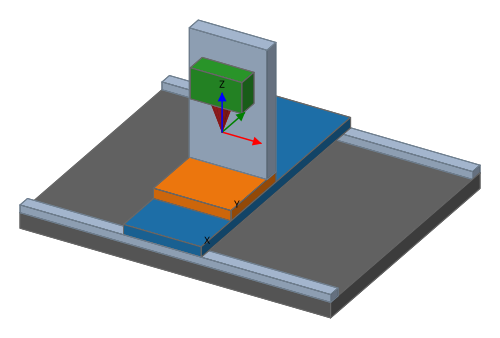

In [3]:
from dataclasses import dataclass

import numpy as np

from minigeo import Cone, Style, Transform

METAL = Style(fill="lightsteelblue", stroke="slategray")


@dataclass
class Stage:
    scene: Scene
    base: Frame
    x: Frame
    y: Frame
    z: Frame
    tip: Frame


def build_stage() -> Stage:
    """Build the XYZ stage with all joints at 0."""
    scene = Scene()
    base = Frame()
    x = base.prismatic("x", limits=(0, 0.8), name="X")  # X carries Y,
    y = x.prismatic("y", limits=(0, 0.6), name="Y")  # Y carries Z
    z = y.prismatic("z", limits=(-0.25, 0), name="Z")

    plate = scene.add(base.attach(Box([0, 0, 0], size=(1.2, 1.0, 0.06), anchor="top")), fill="dimgray")
    for side in ("front", "back"):
        rail = Box(plate.anchor(f"top {side} left"), size=(1.2, 0.05, 0.03), anchor=f"bottom {side} left")
        scene.add(base.attach(rail), METAL)

    x_carriage = Box(plate.anchor("top left") + [0, 0, 0.03], size=(0.3, 1.0, 0.04), anchor="bottom left")
    scene.add(x.attach(x_carriage), fill="C0", label="X", label_at="top front right")

    y_carriage = Box(x_carriage.anchor("top front"), size=(0.3, 0.3, 0.04), anchor="bottom front")
    scene.add(y.attach(y_carriage), fill="C1", label="Y", label_at="top front right")

    column = Box(y_carriage.anchor("top back"), size=(0.3, 0.06, 0.5), anchor="bottom back")
    scene.add(y.attach(column), METAL)

    slider = Box(column.anchor("top front"), size=(0.2, 0.08, 0.12), anchor="top back")
    scene.add(z.attach(slider), fill="C2", label="Z", label_at="front")

    tool = Cone([0, 0, 0], radius=0.04, height=0.12)
    tool.rotate("x", 180, about="center")  # tip down
    tool.place("bottom", at=slider.anchor("bottom"))
    scene.add(z.attach(tool), fill="C3")

    tip = z.fixed(at=tool.anchor("top"), name="tip")
    scene.add_frame(tip, length=0.15, labels=("", "", ""))
    return Stage(scene, base, x, y, z, tip)


stage = build_stage()
stage.x.value = 0.4
stage.y.value = 0.2
stage.z.value = -0.1
print("tool tip at", np.round(stage.tip.origin, 3))
stage.scene

## 3. Three ways to move a part

| what moves | how | in which coordinates |
|---|---|---|
| a joint, along its mechanical axis | `x.value = 0.3`, `x.move(0.05)` | the joint's own axis |
| a part, wherever you want it | `Transform() @ part`, `part.place(...)`, `part.rotate(...)` | world; the part stays attached |
| a part, along a frame's axes | `Transform().translate(...).in_frame(x) @ part` | the frame's x′, y′, z′ |
| a frame's mounting | `Transform() @ frame`, `frame.rotate(...)` | world; the frame carries everything along |

Positions passed in, such as anchors and `at=`, are always world coordinates as things stand
now. Internally, every part is kept relative to its frame, so the joints carry it along later.

Here a camera is mounted on the X carriage, then the whole machine is turned by 30°. X still
slides along its own rail, which is no longer the world x axis, and the camera is shifted
along that rail with `in_frame`:

X axis now points along [ 0.866 -0.5    0.   ]


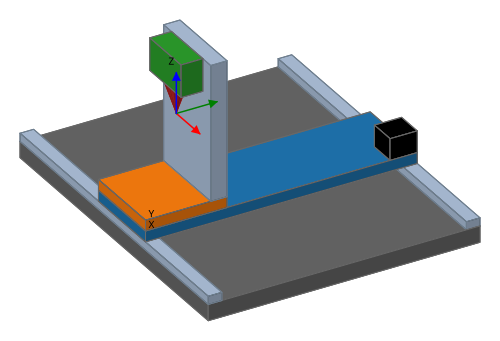

In [4]:
stage = build_stage()
x_carriage = stage.x.attached[0]
camera = Box(x_carriage.anchor("top back"), size=(0.1, 0.1, 0.08), anchor="bottom back")
stage.scene.add(stage.x.attach(camera), fill="black")

stage.base.rotate("z", -30)  # turn the whole machine, camera included
Transform().translate([0.1, 0, 0]).in_frame(stage.x) @ camera  # 0.1 along the X rail
stage.x.value = 0.5  # the joint moves along its own axis too

print("X axis now points along", np.round(stage.x.axis, 3))
stage.scene

## 4. Animated

In the update function the joints get absolute values, so there is nothing to keep track
of and no rounding drift, however many frames there are. Here the tool tip draws a circle and
dips twice per turn. Press ▶ to play.

In [5]:
stage = build_stage()


def update(i, frames=60):
    turn = 2 * np.pi * i / frames
    stage.x.value = 0.25 + 0.2 * np.cos(turn)
    stage.y.value = 0.3 + 0.2 * np.sin(turn)
    stage.z.value = -0.05 * (1 - np.cos(2 * turn))


update(0)
stage.scene.animate(update, frames=60)

## 5. A θ–2θ scan

A two-circle diffractometer has two coaxial revolute joints: θ turns the sample, 2θ the
detector arm. Lines can be attached too, so the diffracted beam follows the arm. The scan
is just `theta.value = θ` and `two_theta.value = 2θ`. Labels can contain math between `$` signs, as in LaTeX.

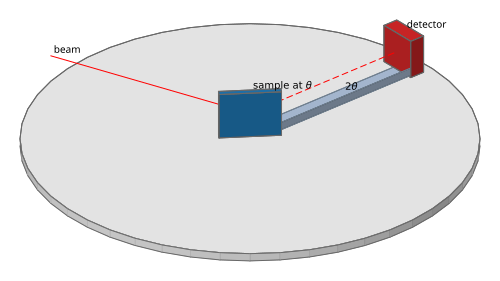

In [6]:
from minigeo import Line

scene = Scene()
height = 0.14  # of the beam above the table
scene.add(Cylinder([0, 0, 0], radius=1.1, height=0.04, anchor="top", segments=48), fill="whitesmoke")

theta = Frame().revolute("z", name="θ")
two_theta = Frame().revolute("z", name="2θ")

# At 0°, the sample surface lies along the incoming beam and the detector looks straight at it.
sample = Box([0, 0, height], size=(0.3, 0.03, 0.24))
scene.add(theta.attach(sample), fill="C0", label=r"sample at $\theta$", label_at="top")

arm = Box([0.15, 0, 0.02], size=(0.85, 0.06, 0.04), anchor="left")
detector = Box(arm.anchor("top right"), size=(0.08, 0.2, 0.2), anchor="bottom right")
outgoing = Line([0, 0, height], detector.anchor("left"))
two_theta.attach(arm, detector, outgoing)
scene.add(arm, METAL, label=r"$2\theta$", label_at="top")
scene.add(detector, fill="C3", label="detector", label_at="top")
scene.add(outgoing, stroke="red", dash="dashed")

scene.add(Line([-1.1, 0, height], [0, 0, height]), stroke="red", arrow=True, label="beam", label_at="start")

theta.value, two_theta.value = 35, 70
scene

In [7]:
def scan(i):
    theta.value = i
    two_theta.value = 2 * i


scan(0)
scene.animate(scan, frames=46)  # θ from 0° to 45°